In [31]:
# ======================================================================================================================================================
#                                           AUTOMATED REPORT FOR ANALYZING LONG-TERM TRENDS IN THE
#                                                      FORMAL LABOR MARKET IN ARGENTINA
# ======================================================================================================================================================

# Objective: To generate a series of charts and calculations based on key indicators, enabling the analysis of long-term trends in formal employment
# in Argentina, alongside data on population and the general level of economic activity (GDP). Furthermore, the report can be easily updated
# as frequently as needed by the user with the most recent data for these variables.

# Data sources:
# Registered workers: https://www.argentina.gob.ar/trabajo/estadisticas/situacion-y-evolucion-del-trabajo-registrado
# Population (2022 onwards): https://www.indec.gob.ar/indec/web/Nivel4-Tema-2-24-84
# Population (prior to 2022): https://github.com/joanfernandez10/Files/blob/main/c2_proyecciones_nac_2010_2040.xls
# GDP: https://www.indec.gob.ar/indec/web/Nivel4-Tema-3-9-47

In [6]:
# ==============================================================================
# LOADING LIBRARIES AND DATA SOURCES
# ==============================================================================

# ------------------------------------------------------------------------------
# Libraries:
# ------------------------------------------------------------------------------

from datetime import datetime
from matplotlib import cm
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, display
import numpy as np
import re
import warnings
# Specifically ignore openpyxl warnings about unknown extensions
warnings.filterwarnings(
    'ignore', category=UserWarning, module='openpyxl.worksheet._reader')

# ------------------------------------------------------------------------------
# File loading (Change only the name of these files to the most recent ones 
# to update the report):
# ------------------------------------------------------------------------------

WORK_FILE = 'trabajoregistrado_2607_estadisticas.xlsx'
GDP_FILE = 'sh_oferta_demanda_09_26.xls'
POPULATION_FILE_1 = 'c2_proyecciones_nac_2010_2040.xls'
POPULATION_FILE_2 = 'proyecciones_nacionales_2022_2040_c1_c2.xlsx'

# ------------------------------------------------------------------------------
# Create GDP and population dataframes:
# ------------------------------------------------------------------------------

# GDP:
df = pd.read_excel(GDP_FILE, sheet_name='cuadro 1', header=None)
years = []
gdp_values = []
current_year = None
for col in range(df.shape[1]):
  # Row 3 contains the years (e.g. 2004, 2005, ..., 2024 (1))
  val_row3 = df.iloc[3, col]
  if pd.notna(val_row3):
    match = re.search(r'\d{4}', str(val_row3))
    if match:
      current_year = int(match.group(0))
  # Row 4 contains the quarters and the annual 'Total' column
  val_row4 = df.iloc[4, col]
  if pd.notna(val_row4) and str(val_row4).strip() == 'Total':
    if current_year is not None:
      # Row 6 corresponds to Gross Domestic Product (B1b) values
      gdp_val = df.iloc[6, col]
      years.append(current_year)
      gdp_values.append(gdp_val)
df_gdp = pd.DataFrame({'Year': years, 'GDP': gdp_values})
# Show the first rows of the created DataFrame
print(df_gdp.head(5))

# Population:
# 1. HISTORICAL FILE PROCESSING (2010 - 2021)
df_old_raw = pd.read_excel(POPULATION_FILE_1, header=None)
# Extract years from row 5 (columns 1 to 12 for years 2010 to 2021)
years_old = [int(y) for y in df_old_raw.iloc[5, 1:13].values]
# Extract age groups and population values (rows 10 to 28)
rows_old = []
for idx in range(10, df_old_raw.shape[0]):
  age_group = df_old_raw.iloc[idx, 0]
  if pd.isna(age_group):
    break
  values = df_old_raw.iloc[idx, 1:13].values
  rows_old.append([age_group] + list(values))
columns_old = ['Age_Group'] + years_old
df_old_clean = pd.DataFrame(rows_old, columns=columns_old)
# Melt to get a clean format: [Age_Group, Year, Population]
df_old_melted = df_old_clean.melt(
    id_vars=['Age_Group'], var_name='Year', value_name='Population'
)
df_old_melted['Year'] = df_old_melted['Year'].astype(int)
# 2. RECENT FILE PROCESSING AND GROUPING (2022 - 2040)
df_new_raw = pd.read_excel(POPULATION_FILE_2, sheet_name='Cuadro 2.1', header=None)                    
# Extract years (row 2, columns 1 onwards)
years_new = [int(y) for y in df_new_raw.iloc[2, 1:].values]
# Extract single ages and their values (from row 5 to 105)
rows_new = []
for idx in range(5, 107):
  val_age = df_new_raw.iloc[idx, 0]
  if pd.isna(val_age):
    continue
  age_str = str(val_age).strip()
  values = df_new_raw.iloc[idx, 1:].values
  if '100' in age_str:
    age_num = 100
  else:
    try:
      age_num = int(float(age_str))
    except:
      continue
  rows_new.append([age_num] + list(values))
cols_new = ['Age'] + years_new
df_new_simple = pd.DataFrame(rows_new, columns=cols_new)
# Function to map single ages to 5-year age groups
def assign_5year_group(age):
  if age >= 100:
    return '100 and over'
  q_start = (age // 5) * 5
  q_end = q_start + 4
  return f'{q_start}-{q_end}'
df_new_simple['Age_Group'] = df_new_simple['Age'].apply(
    assign_5year_group
)
# Group by summing single ages for each 5-year group
df_new_grouped = (
    df_new_simple.drop(columns=['Age'])
    .groupby('Age_Group')
    .sum()
    .reset_index()
)
# Melt the new dataframe
df_new_melted = df_new_grouped.melt(
    id_vars=['Age_Group'], var_name='Year', value_name='Population'
)
df_new_melted['Year'] = df_new_melted['Year'].astype(int)
# 3. FILTER AND UNIFY BOTH SERIES INTO A SINGLE DATAFRAME
df_old_filtered = df_old_melted[df_old_melted['Year'] <= 2021]
df_new_filtered = df_new_melted[df_new_melted['Year'] >= 2022]
# Concatenate both series into one
df_unified_population = pd.concat(
    [df_old_filtered, df_new_filtered], ignore_index=True
)
# Sort by Year and Age Group
df_unified_population = df_unified_population.sort_values(
    by=['Year', 'Age_Group']
).reset_index(drop=True)
# Preview of the resulting unified DataFrame
print(df_unified_population.head(22))

C:\Users\outlet\AppData\Local\Temp\ipykernel_23100\2679721438.py:36: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(GDP_FILE, sheet_name='cuadro 1', header=None)


Year            GDP
0  2004  485115.195206
1  2005  528055.942503
2  2006  570549.404221
3  2007  621942.502646
4  2008  647176.159741

C:\Users\outlet\AppData\Local\Temp\ipykernel_23100\2679721438.py:61: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df_old_raw = pd.read_excel(POPULATION_FILE_1, header=None)


Age_Group  Year  Population
0        0- 4  2010   3571540.0
1       10-14  2010   3541954.0
2   100 y más  2010      3496.0
3       15-19  2010   3559813.0
4       20-24  2010   3346483.0
5       25-29  2010   3166874.0
6       30-34  2010   3112375.0
7       35-39  2010   2711144.0
8       40-44  2010   2347809.0
9       45-49  2010   2212137.0
10        5-9  2010   3507135.0
11      50-54  2010   2062422.0
12      55-59  2010   1877071.0
13      60-64  2010   1628569.0
14      65-69  2010   1304566.0
15      70-74  2010   1029030.0
16      75-79  2010    808031.0
17      80-84  2010    567436.0
18      85-89  2010    300955.0
19      90-94  2010    104982.0
20      95-99  2010     24631.0
21       0- 4  2011   3622962.0

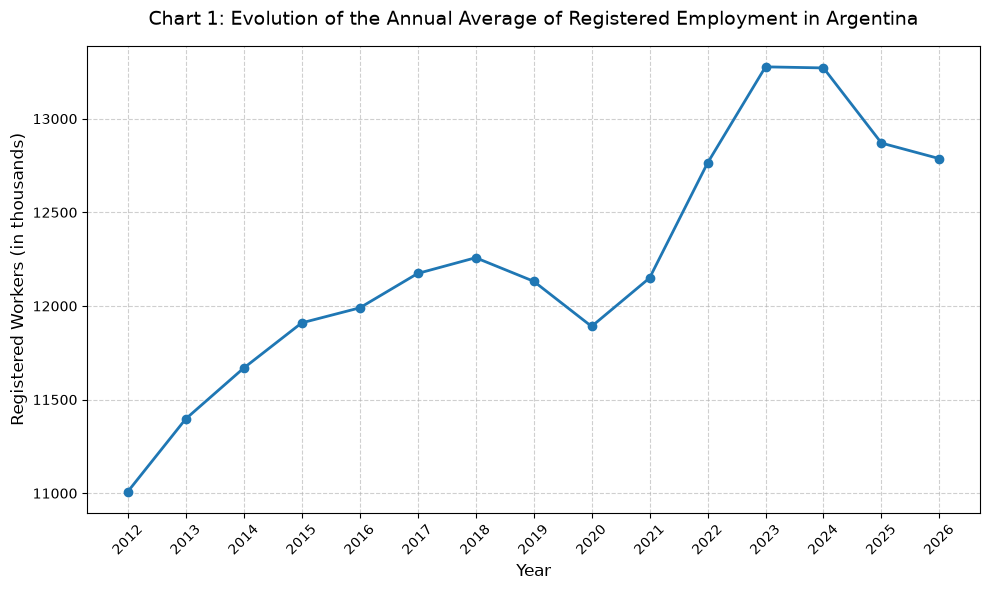

In [7]:
# ==============================================================================
# Chart 1
# ==============================================================================

# Read the relevant tab
df = pd.read_excel(WORK_FILE, sheet_name='T.1', header=2)
# Rename columns
df.columns = [
    'Raw_Date',
    'Original_Series',
    'Seasonally_Adjusted_Series',
    'Original_Index',
    'Seasonally_Adjusted_Index',
    'Back',
]
# Filter empty rows
df = df.dropna(subset=['Raw_Date', 'Original_Series'])
# Function to flexibly extract the year
def extract_year(val):
  if pd.isna(val):
    return None
  if isinstance(val, (pd.Timestamp, datetime)):
    return val.year
  val_str = str(val).strip().lower()
  months = {
      'jan': 1,
      'feb': 2,
      'mar': 3,
      'apr': 4,
      'may': 5,
      'jun': 6,
      'jul': 7,
      'aug': 8,
      'sep': 9,
      'oct': 10,
      'nov': 11,
      'dec': 12,
  }
  for m_name in months:
    if m_name in val_str:
      parts = val_str.replace('*', '').split('-')
      for p in parts:
        p_clean = p.strip()
        if p_clean.isdigit() and len(p_clean) == 2:
          yr = int(p_clean)
          return yr + (2000 if yr < 50 else 1900)
        elif p_clean.isdigit() and len(p_clean) == 4:
          return int(p_clean)
  try:
    return pd.to_datetime(val).year
  except:
    return None
# Extract the year and calculate the annual average
df['Year'] = df['Raw_Date'].apply(extract_year)
df = df.dropna(subset=['Year'])
df['Year'] = df['Year'].astype(int)
df_annual = df.groupby('Year')['Original_Series'].mean().reset_index()
# LINE CHART GENERATION
plt.figure(figsize=(10, 6))
plt.plot(
    df_annual['Year'],
    df_annual['Original_Series'],
    marker='o',
    color='tab:blue',
    linestyle='-',
    linewidth=2,
)
plt.title(
    'Chart 1: Evolution of the Annual Average of Registered Employment in Argentina',
    fontsize=14,
    pad=15,
)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Registered Workers (in thousands)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(df_annual['Year'], rotation=45)
plt.tight_layout()
plt.show()

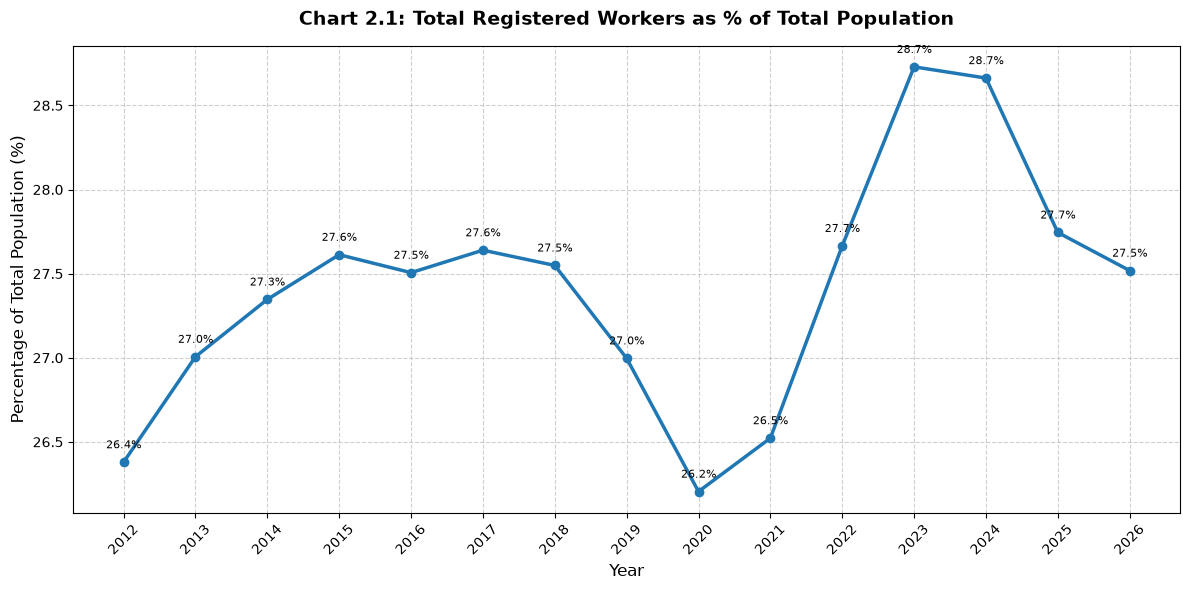

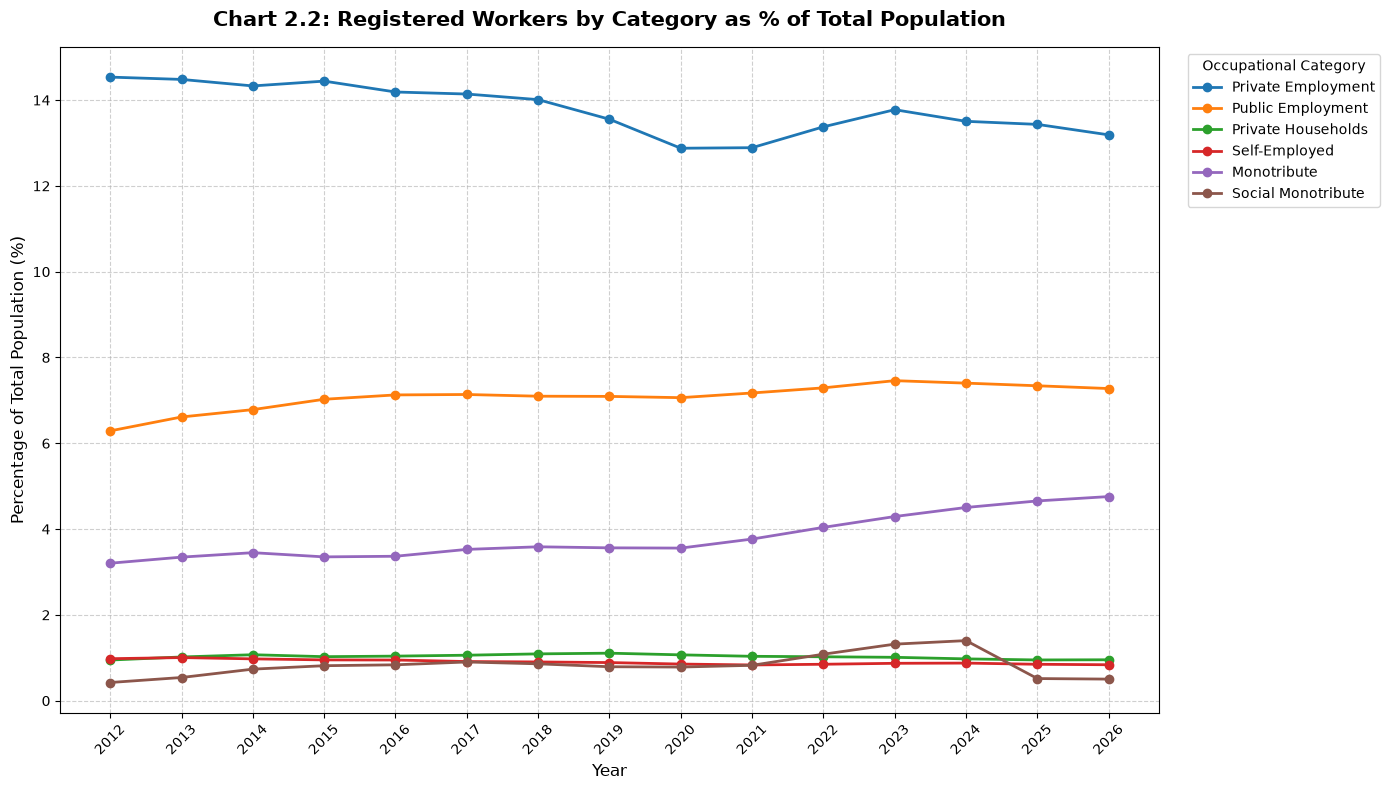

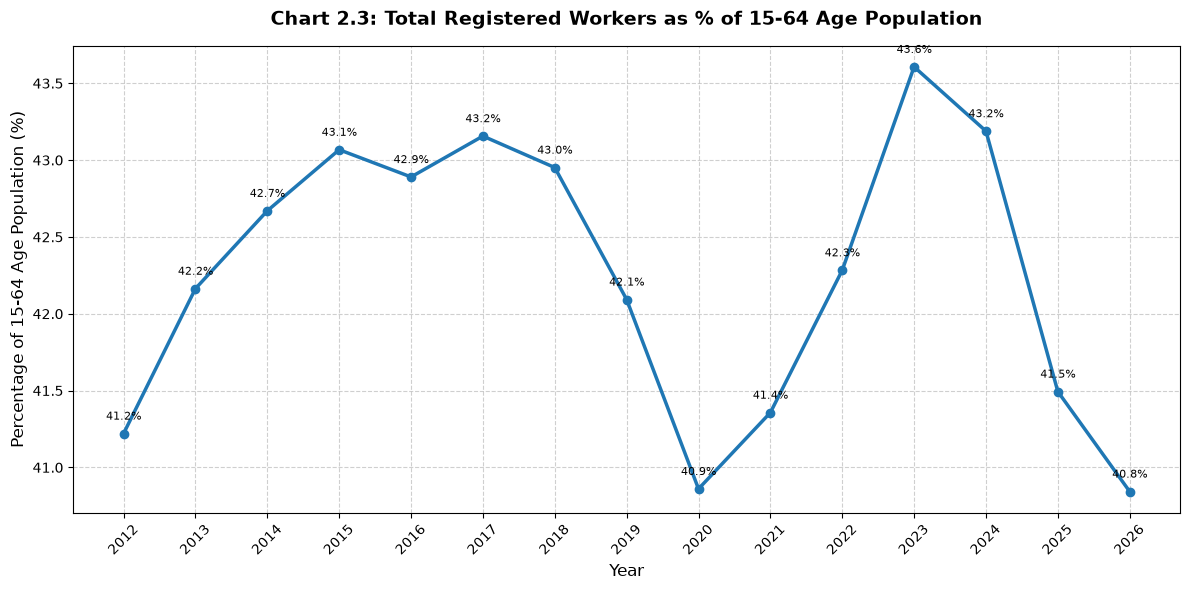

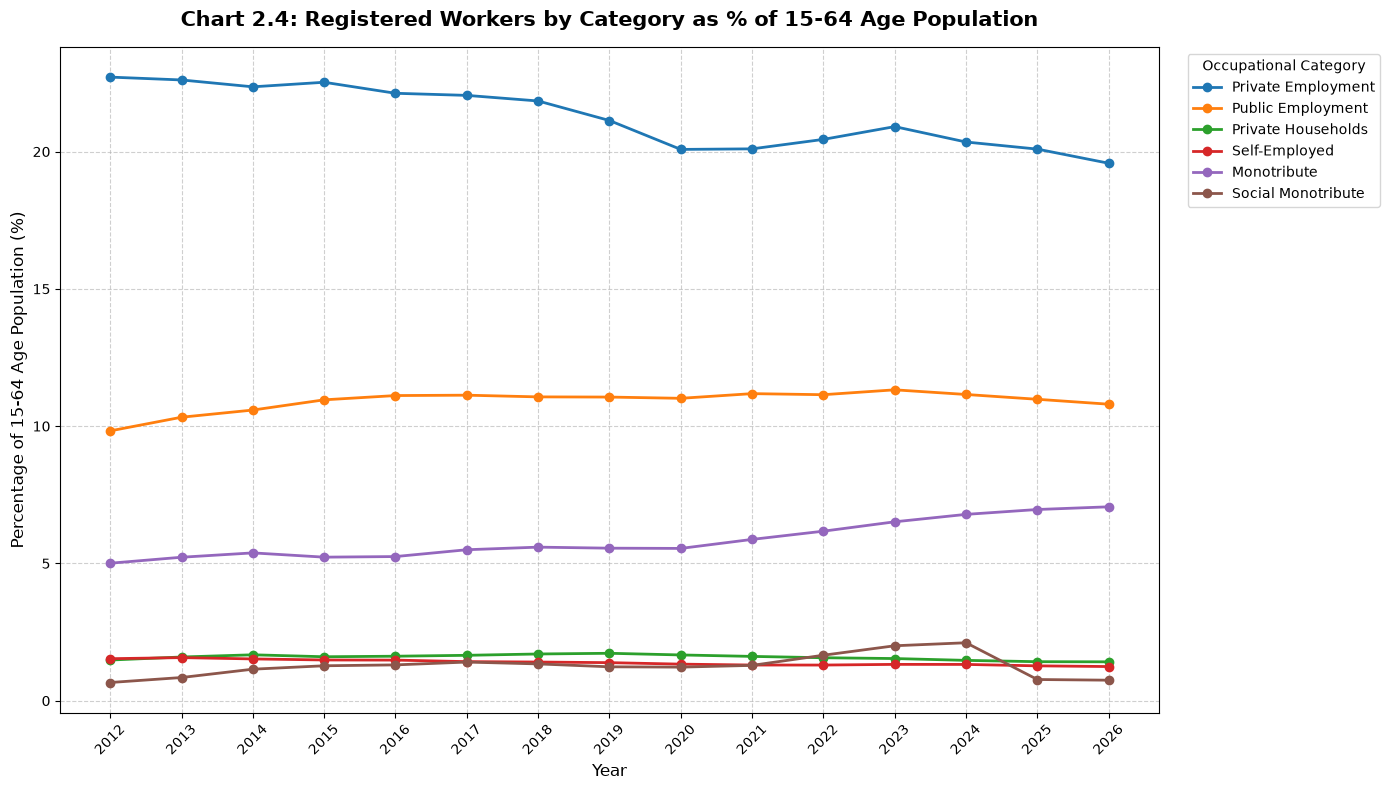

In [8]:
# ==============================================================================
# Charts 2
# ==============================================================================

# 1. POPULATION PROCESSING (Total and 15-64 years)
groups_15_64 = [f"{i}-{i+4}" for i in range(15, 65, 5)]
df_pop_total = (
    df_unified_population.groupby('Year')['Population']
    .sum()
    .reset_index(name='Total_Population')
)
df_pop_15_64 = (
    df_unified_population[
        df_unified_population['Age_Group'].isin(groups_15_64)
    ]
    .groupby('Year')['Population']
    .sum()
    .reset_index(name='Pop_15_64')
)
# 2. REGISTERED EMPLOYMENT PROCESSING (Sheets T.1 and T.2.1)
# Sheet T.1 (Totals)
df_t1 = pd.read_excel(WORK_FILE, sheet_name='T.1', header=2)
df_t1.columns = [
    'Raw_Date',
    'Original_Series',
    'Seasonally_Adjusted_Series',
    'Original_Index',
    'Seasonally_Adjusted_Index',
    'Back',
][: len(df_t1.columns)]
df_t1 = df_t1.dropna(subset=['Raw_Date', 'Original_Series'])
df_t1['Year'] = df_t1['Raw_Date'].apply(extract_year)
df_t1_annual = df_t1.groupby('Year')['Original_Series'].mean().reset_index()
df_t1_annual['Abs_Workers'] = df_t1_annual['Original_Series'] * 1000
# Sheet T.2.1 (By categories)
df_t21 = pd.read_excel(WORK_FILE, sheet_name='T.2.1', header=1)
df_t21.columns = [
    'Raw_Date',
    'Private',
    'Public',
    'Private_Households',
    'Self_Employed',
    'Monotribute',
    'Social_Monotribute',
    'Total',
    'Extra',
][: len(df_t21.columns)]
df_t21 = df_t21.dropna(subset=['Raw_Date', 'Private'])
df_t21['Year'] = df_t21['Raw_Date'].apply(extract_year)
categories = [
    'Private',
    'Public',
    'Private_Households',
    'Self_Employed',
    'Monotribute',
    'Social_Monotribute',
    'Total',
]
df_t21[categories] = (
    df_t21[categories].apply(pd.to_numeric, errors='coerce') * 1000
)
df_t21_annual = df_t21.groupby('Year')[categories].mean().reset_index()
# 3. DATA MERGES (Total Population vs. 15-64 Population)
df_m_tot = pd.merge(df_pop_total, df_t1_annual, on='Year')
df_m_tot['Percentage'] = (
    df_m_tot['Abs_Workers'] / df_m_tot['Total_Population']
) * 100
df_m_tot_cats = pd.merge(df_pop_total, df_t21_annual, on='Year')
cats_, cats_tot = categories[:-1], categories[-1]
for c in categories:
  df_m_tot_cats[f'Pct_{c}'] = (
      df_m_tot_cats[c] / df_m_tot_cats['Total_Population']
  ) * 100
df_m_1564 = pd.merge(df_pop_15_64, df_t21_annual, on='Year')
for c in categories:
  df_m_1564[f'Pct_{c}'] = (df_m_1564[c] / df_m_1564['Pop_15_64']) * 100
# Common styles
readable_names = {
    'Private': 'Private Employment',
    'Public': 'Public Employment',
    'Private_Households': 'Private Households',
    'Self_Employed': 'Self-Employed',
    'Monotribute': 'Monotribute',
    'Social_Monotribute': 'Social Monotribute',
}
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
# Helper function for line plots
def plot_line(df, x_col, y_col, title, ylabel):
  plt.figure(figsize=(12, 6))
  plt.plot(
      df[x_col], df[y_col], marker='o', color='tab:blue', linewidth=2.5
  )
  plt.title(title, fontsize=14, fontweight='bold', pad=15)
  plt.xlabel('Year', fontsize=12)
  plt.ylabel(ylabel, fontsize=12)
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.xticks(df[x_col], rotation=45)
  for yr, pct in zip(df[x_col], df[y_col]):
    plt.annotate(
        f'{pct:.1f}%',
        (yr, pct),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center',
        fontsize=8,
    )
  plt.tight_layout()
  plt.show()
def plot_multilines(df, x_col, cats, title, ylabel):
  plt.figure(figsize=(14, 8))
  for cat, col in zip(cats, colors):
    plt.plot(
        df[x_col],
        df[f'Pct_{cat}'],
        marker='o',
        linewidth=2,
        label=readable_names[cat],
        color=col,
    )
  plt.title(title, fontsize=15, fontweight='bold', pad=15)
  plt.xlabel('Year', fontsize=12)
  plt.ylabel(ylabel, fontsize=12)
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.xticks(df[x_col], rotation=45)
  plt.legend(
      title='Occupational Category', bbox_to_anchor=(1.02, 1), loc='upper left'
  )
  plt.tight_layout()
  plt.show()
# 4. GENERATION OF THE 4 CHARTS
# Chart 1: Totals as % of Total Population
plot_line(
    df_m_tot,
    'Year',
    'Percentage',
    'Chart 2.1: Total Registered Workers as % of Total Population',
    'Percentage of Total Population (%)',
)
# Chart 2: Categories as % of Total Population
plot_multilines(
    df_m_tot_cats,
    'Year',
    cats_,
    'Chart 2.2: Registered Workers by Category as % of Total Population',
    'Percentage of Total Population (%)',
)
# Chart 3: Totals as % of 15-64 Population
plot_line(
    df_m_1564,
    'Year',
    'Pct_Total',
    'Chart 2.3: Total Registered Workers as % of 15-64 Age Population',
    'Percentage of 15-64 Age Population (%)',
)
# Chart 4: Categories as % of 15-64 Population
plot_multilines(
    df_m_1564,
    'Year',
    cats_,
    'Chart 2.4: Registered Workers by Category as % of 15-64 Age Population',
    'Percentage of 15-64 Age Population (%)',
)

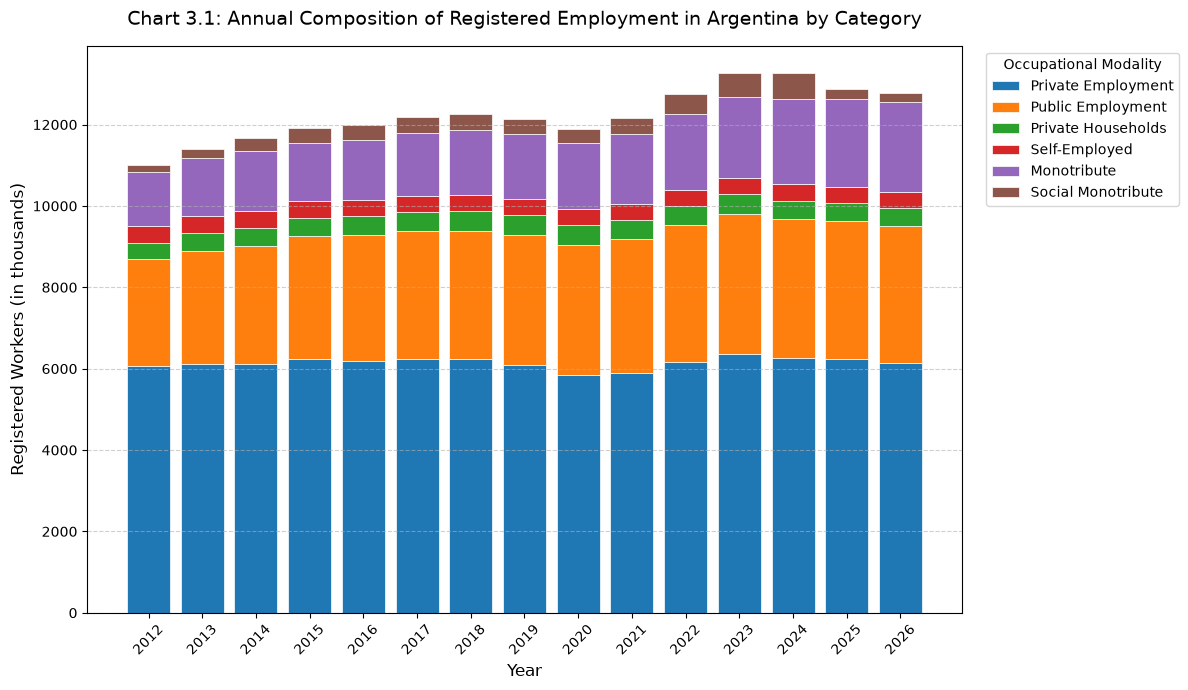

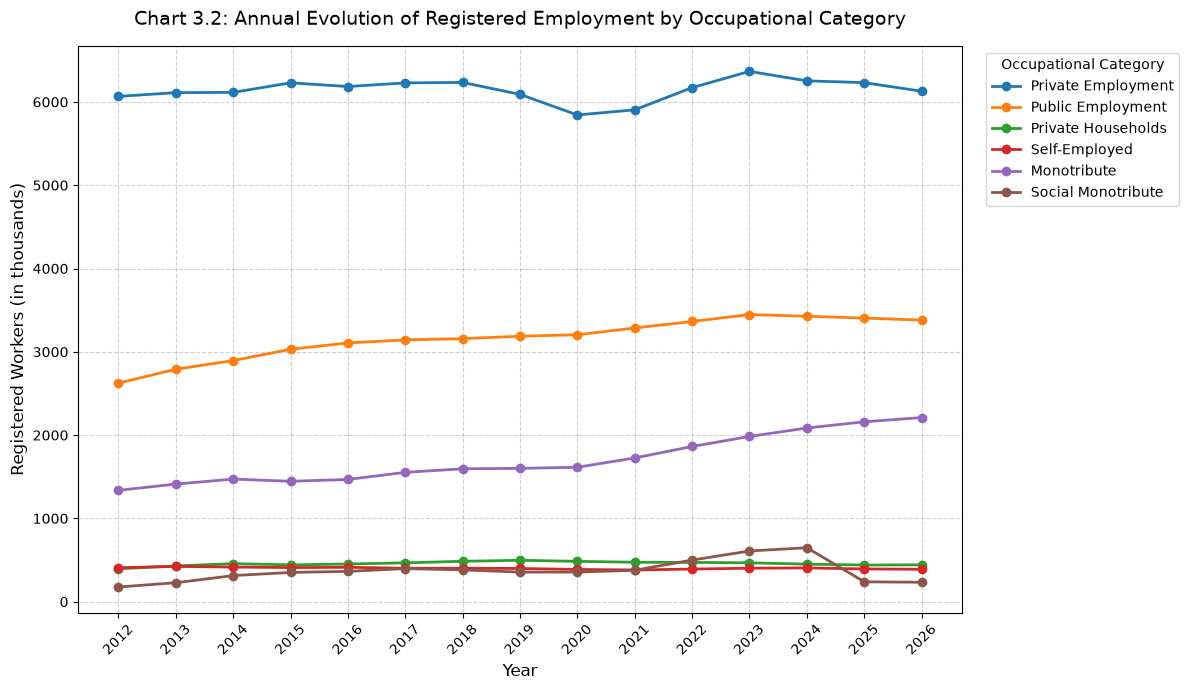

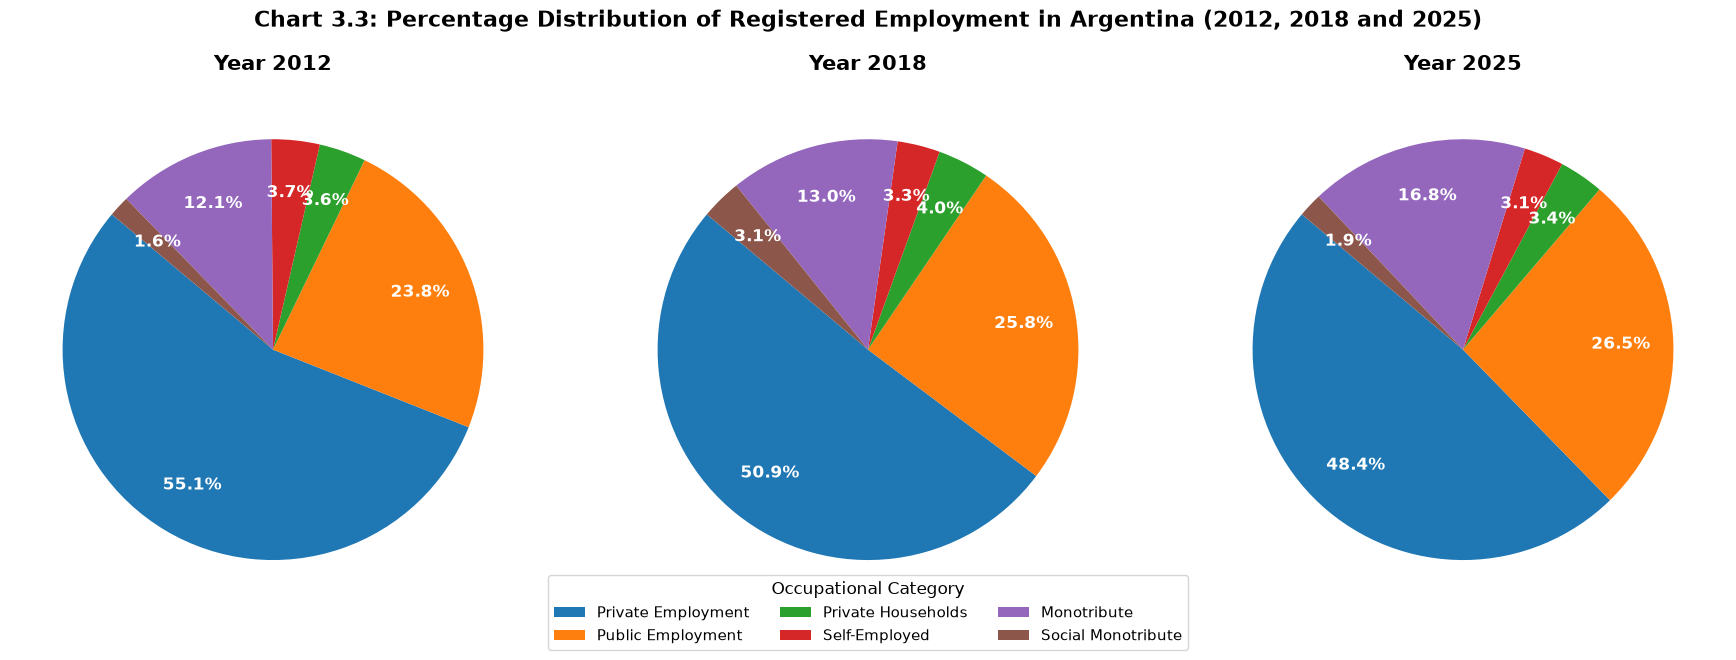

In [9]:
# ==============================================================================
# Charts 3
# ==============================================================================

# 1. DATA LOADING AND PROCESSING (Tab T.2.1)
df = pd.read_excel(WORK_FILE, sheet_name='T.2.1', header=1)
df.columns = [
    'Raw_Date',
    'Private',
    'Public',
    'Private_Households',
    'Self_Employed',
    'Monotribute',
    'Social_Monotribute',
    'Total',
    'Extra',
][: len(df.columns)]
df = df.dropna(subset=['Raw_Date', 'Private'])
def extract_year(val):
  if pd.isna(val):
    return None
  if isinstance(val, (pd.Timestamp, datetime)):
    return val.year
  val_str = str(val).strip().lower()
  for m in [
      'jan',
      'feb',
      'mar',
      'apr',
      'may',
      'jun',
      'jul',
      'aug',
      'sep',
      'oct',
      'nov',
      'dec',
  ]:
    if m in val_str:
      parts = [
          p.strip()
          for p in val_str.replace('*', '').split('-')
          if p.strip().isdigit()
      ]
      if parts:
        yr = int(parts[0])
        return yr + (2000 if yr < 50 else 1900) if len(parts[0]) == 2 else yr
  try:
    return pd.to_datetime(val).year
  except:
    return None
df['Year'] = df['Raw_Date'].apply(extract_year)
df = df.dropna(subset=['Year'])
df['Year'] = df['Year'].astype(int)
categories = [
    'Private',
    'Public',
    'Private_Households',
    'Self_Employed',
    'Monotribute',
    'Social_Monotribute',
]
for cat in categories:
  df[cat] = pd.to_numeric(df[cat], errors='coerce')
# Grouped annual DataFrame (with 'Year' index and standard format)
df_annual = df.groupby('Year')[categories].mean().reset_index()
# Color palette and common readable names
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
readable_names = [
    'Private Employment',
    'Public Employment',
    'Private Households',
    'Self-Employed',
    'Monotribute',
    'Social Monotribute',
]
years = df_annual['Year']
# 2. CHART 1: STACKED VERTICAL BARS
fig, ax = plt.subplots(figsize=(12, 7))
bottom = None
for i, cat in enumerate(categories):
  values = df_annual[cat]
  ax.bar(
      years,
      values,
      bottom=bottom,
      label=readable_names[i],
      color=colors[i],
      edgecolor='white',
      linewidth=0.5,
  )
  bottom = values.copy() if bottom is None else bottom + values
ax.set_title(
    'Chart 3.1: Annual Composition of Registered Employment in Argentina by Category',
    fontsize=14,
    pad=15,
)
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Registered Workers (in thousands)', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(years, rotation=45)
ax.legend(title='Occupational Modality', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
# 3. CHART 2: EVOLUTION LINES BY CATEGORY
plt.figure(figsize=(12, 7))
for i, cat in enumerate(categories):
  plt.plot(
      years,
      df_annual[cat],
      marker='o',
      linewidth=2,
      label=readable_names[i],
      color=colors[i],
  )
plt.title(
    'Chart 3.2: Annual Evolution of Registered Employment by Occupational Category',
    fontsize=14,
    pad=15,
)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Registered Workers (in thousands)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(years, rotation=45)
plt.legend(title='Occupational Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
# 4. CHART 3: THREE PIE CHARTS (2012, 2018 and 2025)
YEARS_TO_PLOT = [2012, 2018, 2025]
df_annual_indexed = df_annual.set_index('Year')
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for i, year in enumerate(YEARS_TO_PLOT):
  ax = axes[i]
  if year in df_annual_indexed.index:
    values = df_annual_indexed.loc[year]
    wedges, texts, autotexts = ax.pie(
        values,
        labels=None,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        pctdistance=0.75,
        textprops=dict(color='white', fontweight='bold', fontsize=12),
    )
    ax.set_title(f'Year {year}', fontsize=15, fontweight='bold', pad=12)
  else:
    ax.text(
        0.5,
        0.5,
        f'No data for {year}',
        ha='center',
        va='center',
        transform=ax.transAxes,
        fontsize=12,
    )
fig.legend(
    wedges,
    readable_names,
    title='Occupational Category',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.05),
    ncol=3,
    fontsize=11,
    title_fontsize=12,
)
plt.suptitle(
    'Chart 3.3: Percentage Distribution of Registered Employment in Argentina (2012, 2018'
    ' and 2025)',
    fontsize=16,
    fontweight='bold',
    y=1.03,
)
plt.tight_layout()
plt.show()

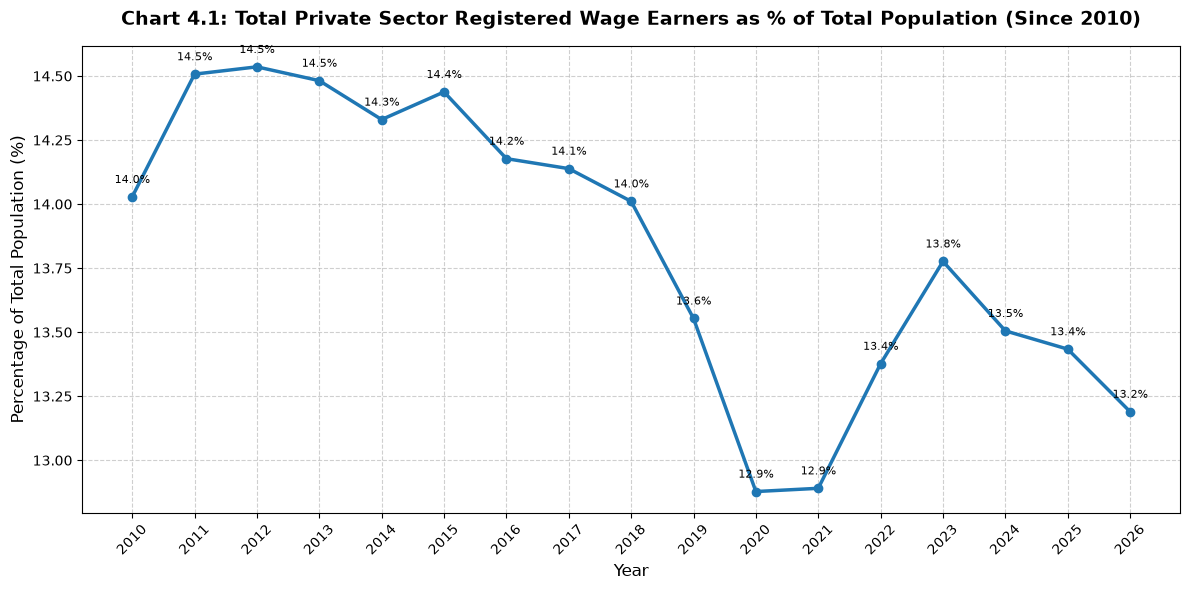

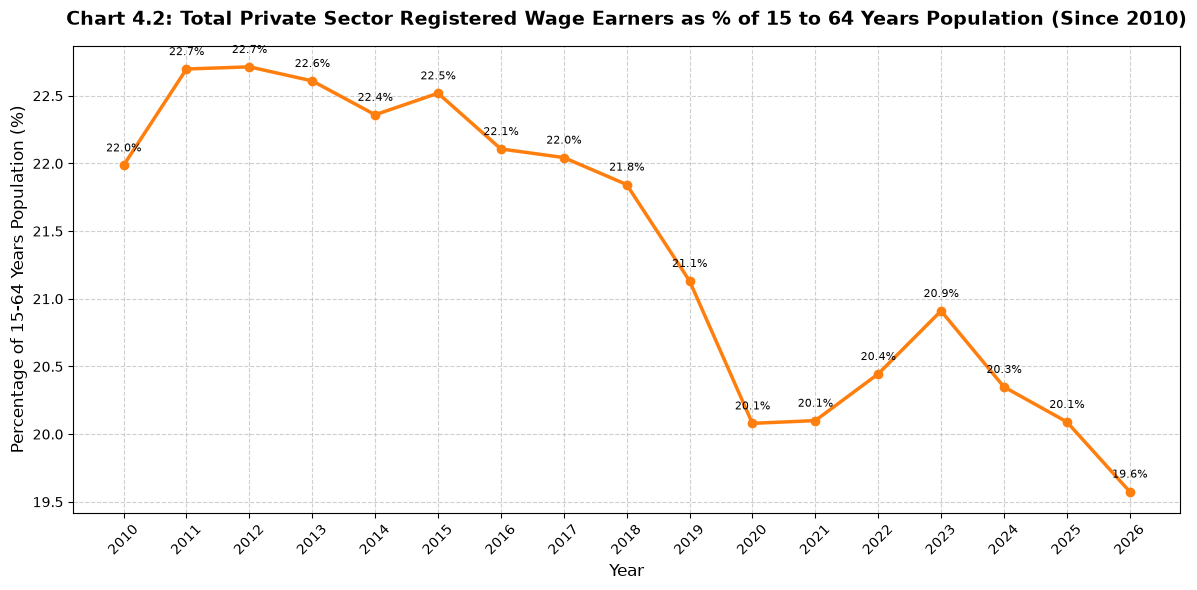

In [10]:
# ==============================================================================
# Charts 4
# ==============================================================================

# 1. PREPARATION OF DEMOGRAPHIC DENOMINATORS (Total Population and 15-64 years)
groups_15_64 = [f'{i}-{i+4}' for i in range(15, 65, 5)]
df_pop_total = (
    df_unified_population.groupby('Year')['Population']
    .sum()
    .reset_index(name='Total_Population')
)
df_pop_15_64 = (
    df_unified_population[
        df_unified_population['Age_Group'].isin(groups_15_64)
    ]
    .groupby('Year')['Population']
    .sum()
    .reset_index(name='Pop_15_64')
)
# 2. REGISTERED WAGE EMPLOYMENT PROCESSING (Sheet A.1)
excel_work = pd.ExcelFile(WORK_FILE)
df_a1 = pd.read_excel(excel_work, sheet_name='A.1', header=2)
df_a1.columns = [
    'Raw_Date',
    'Original_Series',
    'Seasonally_Adjusted_Series',
    'Original_Index',
    'Seasonally_Adjusted_Index',
    'Back',
][: len(df_a1.columns)]
df_a1 = df_a1.dropna(subset=['Raw_Date', 'Original_Series'])
df_a1['Year'] = df_a1['Raw_Date'].apply(extract_year)
df_a1_annual = df_a1.groupby('Year')['Original_Series'].mean().reset_index()
df_a1_annual['Abs_Workers'] = df_a1_annual['Original_Series'] * 1000
# 3. MERGES AND PERCENTAGE CALCULATIONS
df_m_tot = pd.merge(df_pop_total, df_a1_annual, on='Year', how='inner')
df_m_tot['Pct_Total'] = (
    df_m_tot['Abs_Workers'] / df_m_tot['Total_Population']
) * 100
df_m_1564 = pd.merge(df_pop_15_64, df_a1_annual, on='Year', how='inner')
df_m_1564['Pct_1564'] = (
    df_m_1564['Abs_Workers'] / df_m_1564['Pop_15_64']
) * 100
# 4. GENERATION OF THE 2 LINE CHARTS
# Chart 1: Registered Wage Earners as % of Total Population (since 2010)
plt.figure(figsize=(12, 6))
plt.plot(
    df_m_tot['Year'],
    df_m_tot['Pct_Total'],
    marker='o',
    color='tab:blue',
    linewidth=2.5,
    markersize=6,
)
plt.title(
    'Chart 4.1: Total Private Sector Registered Wage Earners as % of Total Population (Since 2010)',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Percentage of Total Population (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(df_m_tot['Year'], rotation=45)
for yr, pct in zip(df_m_tot['Year'], df_m_tot['Pct_Total']):
  plt.annotate(
      f'{pct:.1f}%',
      (yr, pct),
      textcoords='offset points',
      xytext=(0, 10),
      ha='center',
      fontsize=8,
  )
plt.tight_layout()
plt.show()
# Chart 2: Registered Wage Earners as % of 15 to 64 Years Population (since 2010)
plt.figure(figsize=(12, 6))
plt.plot(
    df_m_1564['Year'],
    df_m_1564['Pct_1564'],
    marker='o',
    color='tab:orange',
    linewidth=2.5,
    markersize=6,
)
plt.title(
    'Chart 4.2: Total Private Sector Registered Wage Earners as % of 15 to 64 Years Population'
    ' (Since 2010)',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Percentage of 15-64 Years Population (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(df_m_1564['Year'], rotation=45)
for yr, pct in zip(df_m_1564['Year'], df_m_1564['Pct_1564']):
  plt.annotate(
      f'{pct:.1f}%',
      (yr, pct),
      textcoords='offset points',
      xytext=(0, 10),
      ha='center',
      fontsize=8,
  )
plt.tight_layout()
plt.show()

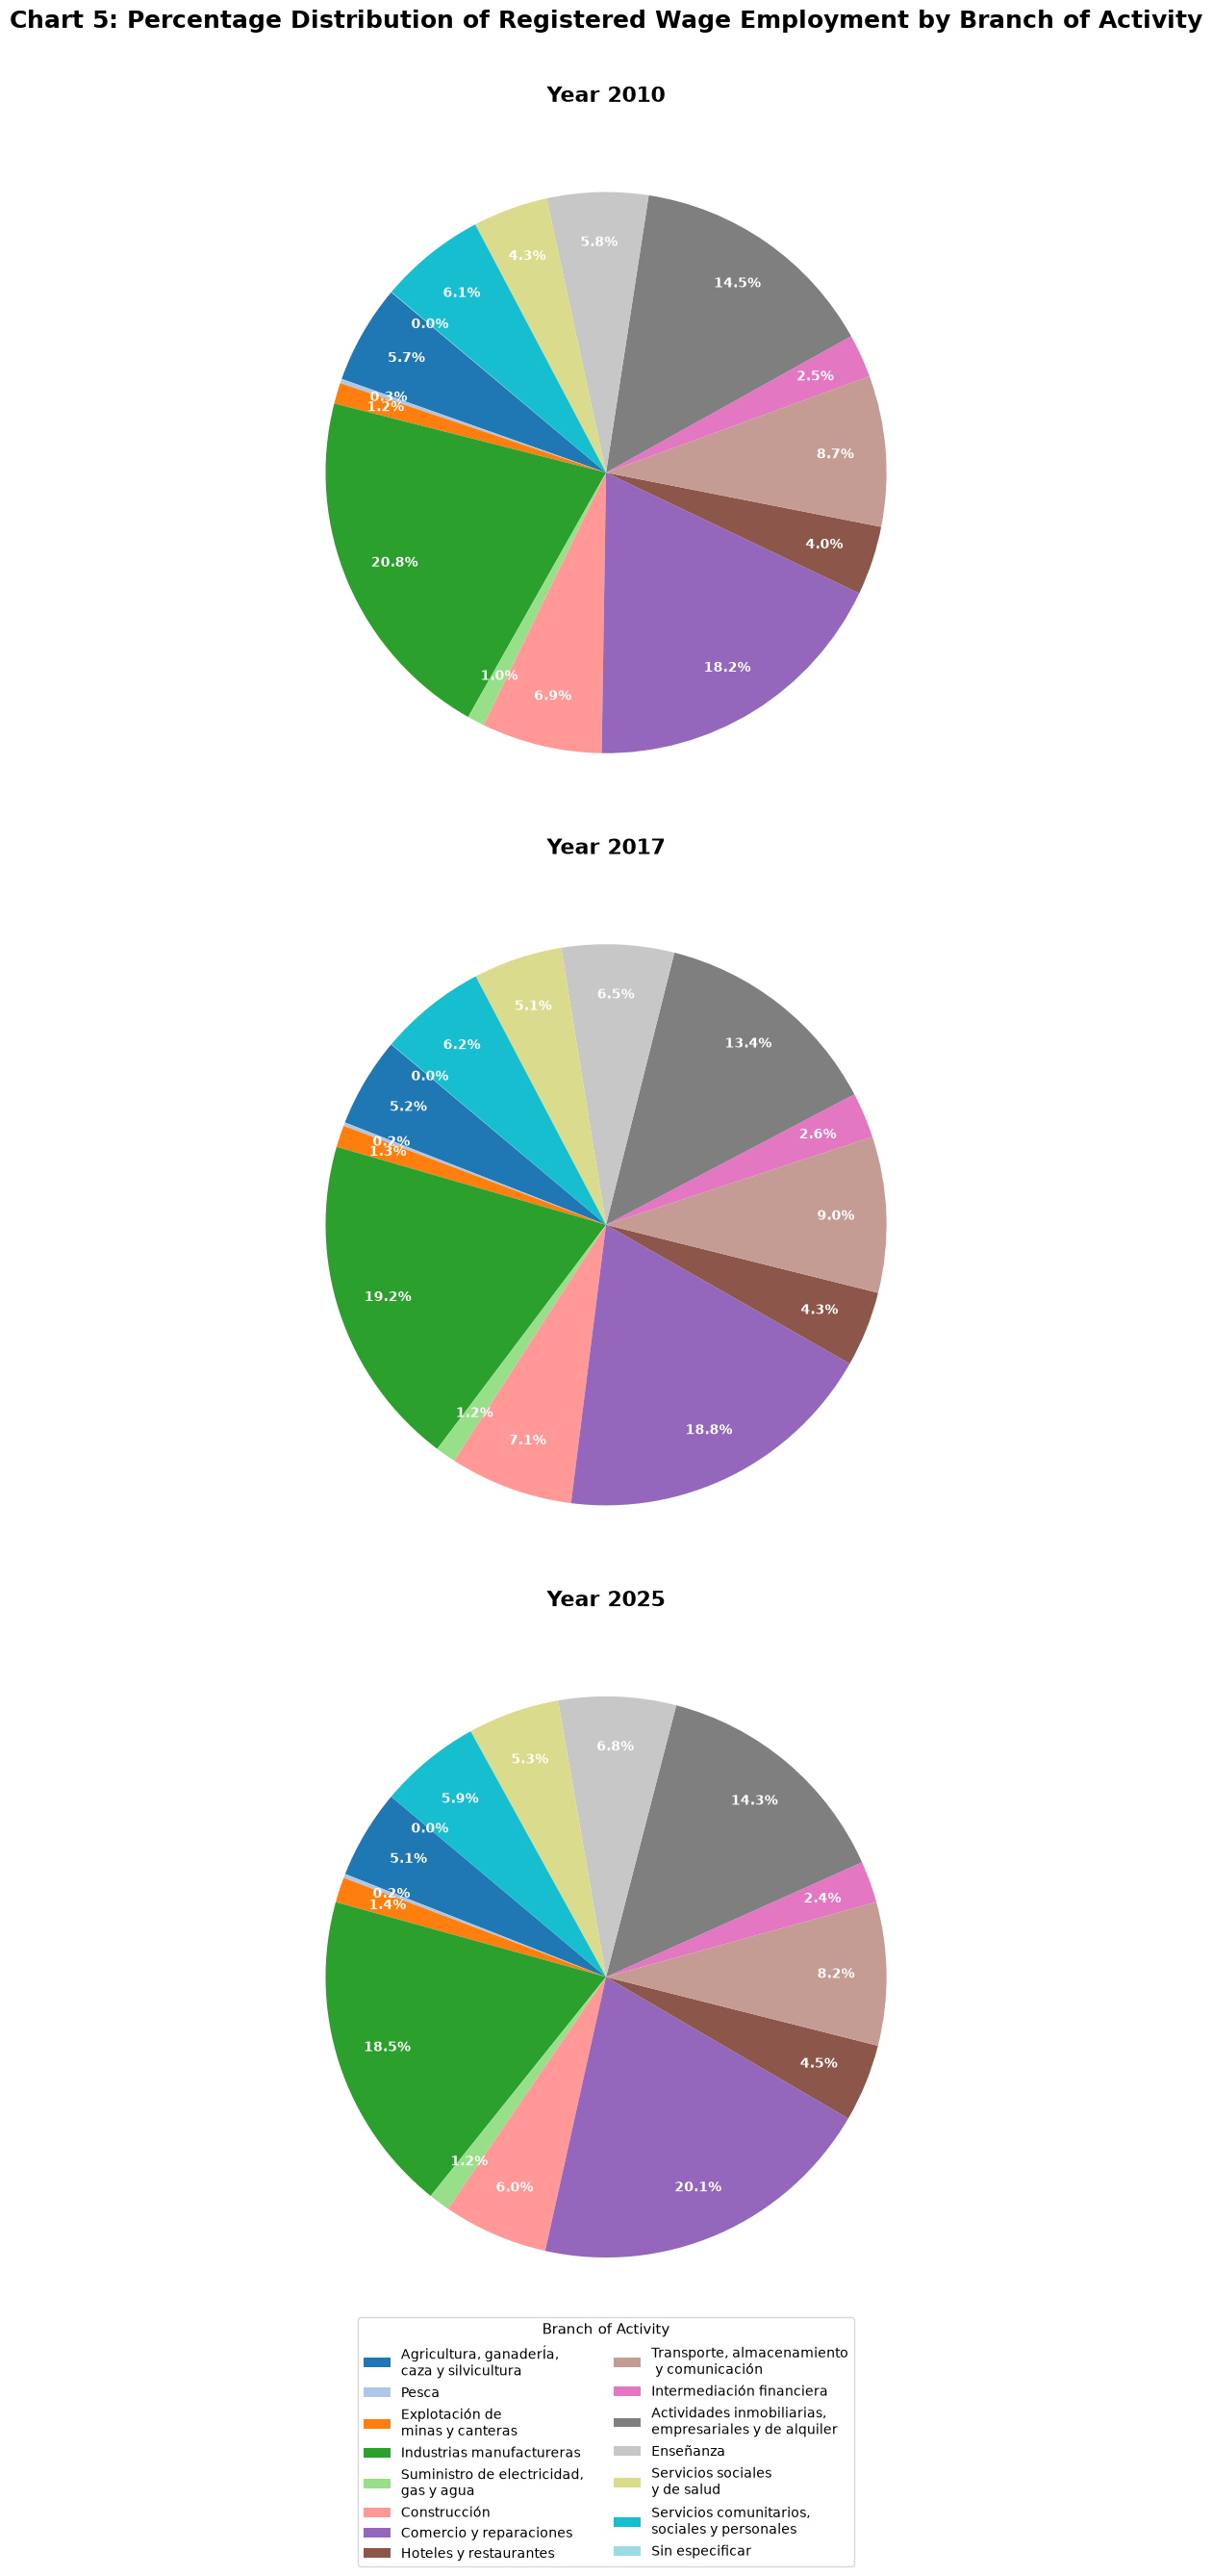

In [11]:
# ==============================================================================
# Chart 5
# ==============================================================================

# ROBUST LOADING AND EXTRACTION 
excel_work = pd.ExcelFile(WORK_FILE)
df_a21_raw = pd.read_excel(excel_work, sheet_name='A.2.1', header=None)
branch_names_b_p = df_a21_raw.iloc[1, 1:16].values
df_a21 = df_a21_raw.iloc[2:].copy()
df_a21.columns = ['Period'] + list(branch_names_b_p) + [
    f'Extra_{i}' for i in range(16, len(df_a21.columns))
]
df_a21 = df_a21.dropna(subset=['Period'])
def extract_year(val):
  try:
    if pd.isna(val):
      return np.nan
    # If it's a Python datetime object (e.g., 2009-01-01)
    if isinstance(val, (datetime, pd.Timestamp)):
      return val.year
    val_str = str(val).strip()
    # If it's an institutional text row / footnote, discard it
    if any(
        x in val_str.lower()
        for x in ['note', 'source', '*', 'provisional', 'employment', 'el empleo']
    ):
      return np.nan
    # Explicitly search for a 4-digit year (e.g., 2017, 2025)
    match_4dig = re.search(r'(19\d{2}|20\d{2})', val_str)
    if match_4dig:
      return int(match_4dig.group(1))
    # If it comes in format like 'feb-15', 'jan-26', etc.
    match_2dig = re.search(r'[a-zA-Z]{3}-(\d{2})', val_str)
    if match_2dig:
      yy = int(match_2dig.group(1))
      # If yy is less than 50 we assume 2000+, otherwise 1900+
      return 2000 + yy if yy < 50 else 1900 + yy
    return np.nan
  except:
    return np.nan
df_a21['Year'] = df_a21['Period'].apply(extract_year)
df_a21 = df_a21.dropna(subset=['Year'])
df_a21['Year'] = df_a21['Year'].astype(int)
branch_cols = list(branch_names_b_p)
for col in branch_cols:
  df_a21[col] = pd.to_numeric(df_a21[col], errors='coerce')
df_a21_annual = (
    df_a21.groupby('Year')[branch_cols].mean().reset_index().set_index('Year')
)
# GENERATION OF THE 3 VERTICAL PIE CHARTS (2010, 2017 and 2025)
YEARS_BRANCHES = [2010, 2017, 2025]
fig, axes = plt.subplots(3, 1, figsize=(10, 24))
branch_colors = cm.tab20(np.linspace(0, 1, len(branch_cols)))
wedges = None
years_already_used = []
for i, target_year in enumerate(YEARS_BRANCHES):
  ax = axes[i]
  candidates = [a for a in df_a21_annual.index if a not in years_already_used]
  if not candidates:
    candidates = list(df_a21_annual.index)
  year_to_use = min(candidates, key=lambda x: abs(x - target_year))
  years_already_used.append(year_to_use)
  if year_to_use in df_a21_annual.index:
    values = df_a21_annual.loc[year_to_use].dropna()
    values = values[values > 0]
    wedges, texts, autotexts = ax.pie(
        values,
        labels=None,
        autopct='%1.1f%%',
        startangle=140,
        colors=branch_colors[: len(values)],
        pctdistance=0.82,
        textprops=dict(color='white', fontweight='bold', fontsize=10),
    )
    ax.set_title(
        f'Year {year_to_use}', fontsize=16, fontweight='bold', pad=15
    )
  else:
    ax.text(
        0.5,
        0.5,
        f'No data for {target_year}',
        ha='center',
        va='center',
        transform=ax.transAxes,
        fontsize=14,
    )
# Unified legend at the bottom
if wedges is not None:
  fig.legend(
      wedges,
      branch_cols[: len(wedges)],
      title='Branch of Activity',
      loc='lower center',
      bbox_to_anchor=(0.5, -0.10),
      ncol=2,
      fontsize=10,
      title_fontsize=11,
  )
plt.suptitle(
    'Chart 5: Percentage Distribution of Registered Wage Employment by Branch of'
    ' Activity',
    fontsize=18,
    fontweight='bold',
    y=1.01,
)
plt.tight_layout()
plt.show()

In [12]:
# ==============================================================================
# Table 1
# ==============================================================================

# CORRECT LOADING OF TAB A.5.1 (Direct absolute values)
excel_work = pd.ExcelFile(WORK_FILE)
def extract_year(val):
  try:
    if pd.isna(val):
      return np.nan
    val_str = str(val).strip()
    if any(
        x in val_str.lower()
        for x in ['note', 'source', '*', 'provisional', 'employment', 'el empleo']
    ):
      return np.nan
    match = re.search(r'(19\d{2}|20\d{2})', val_str)
    if match:
      return int(match.group(1))
    match_2d = re.search(r'[a-zA-Z]{3}-(\d{2})', val_str)
    if match_2d:
      yy = int(match_2d.group(1))
      return 2000 + yy if yy < 50 else 1900 + yy
    return np.nan
  except:
    return np.nan
# Read tab A.5.1 raw
df_a51_raw = pd.read_excel(excel_work, sheet_name='A.5.1', header=None)
# Provinces are from column B to Y (indices 1 to 24 in row 2 / index 1)
prov_names_b_y = df_a51_raw.iloc[1, 1:25].values
# Data starts at row 3 (index 2)
df_a51 = df_a51_raw.iloc[2:].copy()
df_a51.columns = ['Period'] + list(prov_names_b_y) + [
    f'Extra_{i}' for i in range(25, len(df_a51.columns))
]
df_a51 = df_a51.dropna(subset=['Period'])
df_a51['Year'] = df_a51['Period'].apply(extract_year)
df_a51 = df_a51.dropna(subset=['Year'])
df_a51['Year'] = df_a51['Year'].astype(int)
prov_cols = list(prov_names_b_y)
for c in prov_cols:
  df_a51[c] = pd.to_numeric(df_a51[c], errors='coerce')
# Annual average of registered workers by province
a51_annual = df_a51.groupby('Year')[prov_cols].mean()
# PERCENTAGE CALCULATION (Over the total sum of provinces for each year)
table_years = [2009, 2017, 2025]
result = {}
for prov in prov_cols:
  prov_name = str(prov).split('/')[0].strip()
  res_prov = {}
  for year in table_years:
    if year in a51_annual.index:
      year_row = a51_annual.loc[year]
      val_prov = year_row[prov]
      total_provinces = year_row[
          prov_cols
      ].sum()  # Sum of all jurisdictions
      if pd.notna(val_prov) and total_provinces > 0:
        # Exact percentage of the province relative to the provincial total
        res_prov[f'{year}'] = (val_prov / total_provinces) * 100
      else:
        res_prov[f'{year}'] = np.nan
    else:
      res_prov[f'{year}'] = np.nan
  result[prov_name] = res_prov
# Create DataFrame
df_table = pd.DataFrame(result).T
# Sort strictly from highest to lowest based on year 2009
df_table = df_table.sort_values(by='2009', ascending=False)
# Format cells with 2 decimals and % symbol
df_table_format = df_table.map(
    lambda x: f'{x:.2f}%' if pd.notna(x) else 'No data'
)
# SHOW TITLE AND TABLE IN JUPYTER
display(
    HTML(
        '<h4>Table 1: Percentage of total registered private sector wage earners'
        ' corresponding to each province.</h4>'
    )
)
display(df_table_format)

,2009,2017,2025
BUENOS AIRES,31.18%,31.46%,31.60%
Cdad. Autónoma \nde Buenos Aires,26.08%,24.81%,24.13%
SANTA FE,8.09%,8.14%,8.17%
CÓRDOBA,8.08%,8.19%,8.34%
MENDOZA,3.93%,3.92%,3.95%
TUCUMÁN,2.67%,2.69%,2.59%
ENTRE RÍOS,2.20%,2.19%,2.18%
SALTA,1.81%,1.88%,1.96%
RíO NEGRO,1.68%,1.68%,1.78%
CHUBUT,1.62%,1.56%,1.50%


C:\Users\outlet\AppData\Local\Temp\ipykernel_23100\3034210315.py:6: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df_gdp_raw = pd.read_excel(GDP_FILE, sheet_name='cuadro 1', header=None)


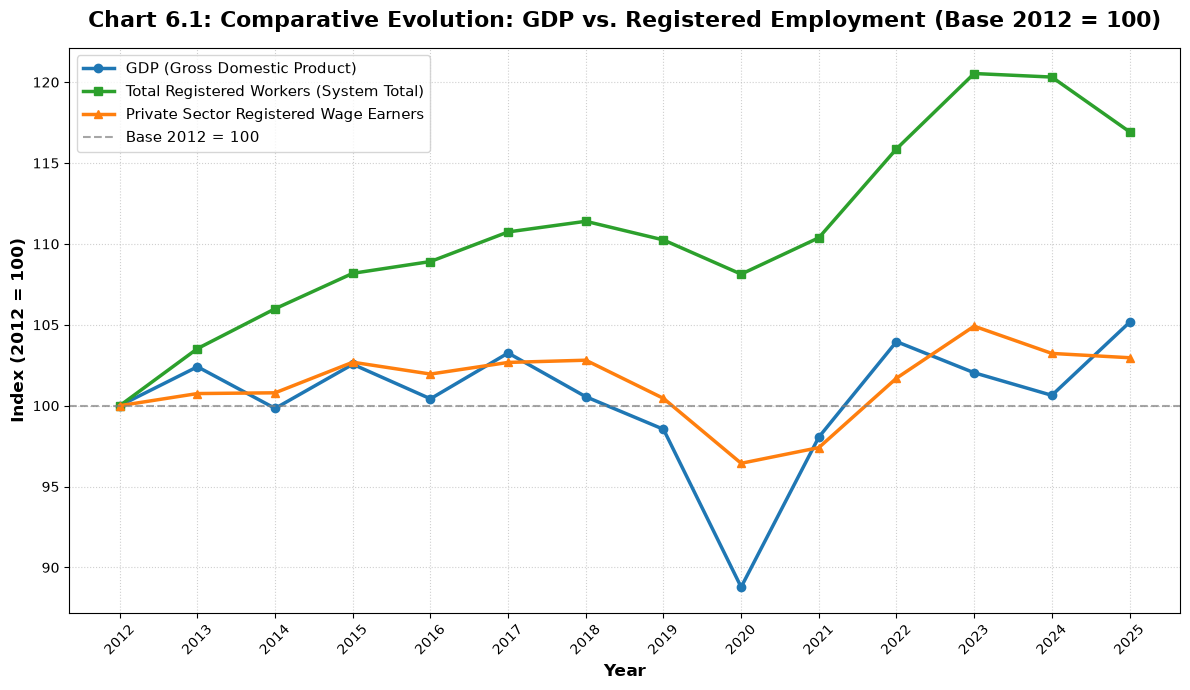

================================================================================

TABLE 2: GROWTH AND ELASTICITY (PRIVATE WAGE EARNERS / GDP)

================================================================================

GDP (Level)  Private Employment (Level)  Var. % GDP  Var. % Private Employment  Annual Elasticity
Year                                                                                                   
2012   703,485.99                    6,066.27         NaN                        NaN                NaN
2013   720,407.11                    6,111.76        2.41                       0.75               0.31
2014   702,306.05                    6,114.56       -2.51                       0.05              -0.02
2015   721,487.15                    6,229.26        2.73                       1.88               0.69
2016   706,477.85                    6,184.87       -2.08                      -0.71               0.34
2017   726,389.95                    6,228.47        2.82                       0.70               0.25
2018   707,377.44                    6,236.79       -2.62                       0.13              -0.05
2019   693,223.80                    6,093.66       -2.00                      -2.29               1.15
2020   624,591.29                    5,850.25       -9.90                      -3.99               0.40
2021   689,809.93                    5,909.02       10.44                       1.00               0.10
2022   731,341.63                    6,169.52        6.02                       4.41               0.73
2023   717,805.73                    6,364.41       -1.85                       3.16              -1.71
2024   707,987.88                    6,262.25       -1.37                      -1.61               1.17
2025   739,728.71                    6,246.11        4.48                      -0.26              -0.06

================================================================================

📊 Accumulated GDP Variation (2012-2025): 5.15%

📊 Accumulated Private Employment Variation (2012-2025): 2.96%

🔗 Total Accumulated Elasticity (Period 2012-2025): 0.5754

================================================================================

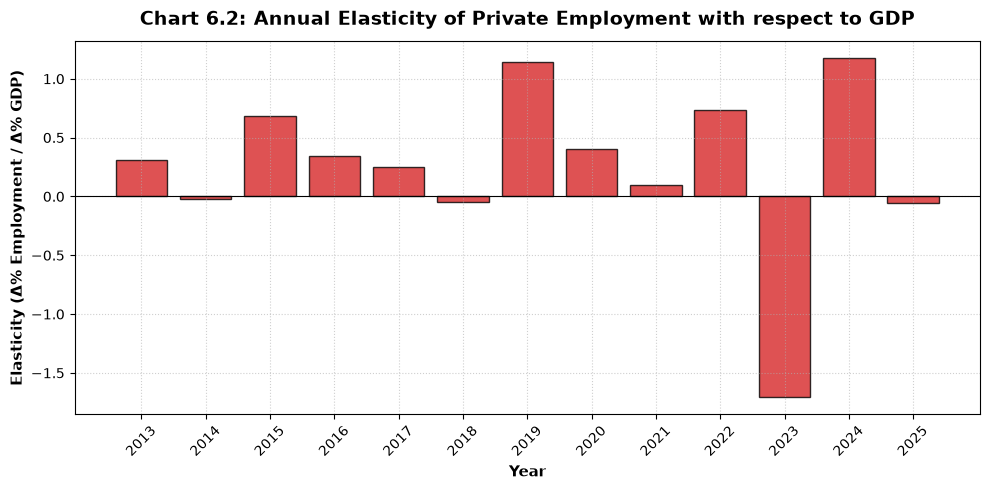

In [14]:
# ==============================================================================
# Charts 6 and Table 2
# ==============================================================================

# 1. GDP EXTRACTION ('cuadro 1' tab from sh_oferta_demanda_09_26.xls)
df_gdp_raw = pd.read_excel(GDP_FILE, sheet_name='cuadro 1', header=None)
gdp_years = []
gdp_values = []
current_year = None
for col in range(df_gdp_raw.shape[1]):
  val_row3 = df_gdp_raw.iloc[3, col]
  if pd.notna(val_row3):
    match = re.search(r'\d{4}', str(val_row3))
    if match:
      current_year = int(match.group(0))
  val_row4 = df_gdp_raw.iloc[4, col]
  if pd.notna(val_row4) and str(val_row4).strip() == 'Total':
    if current_year is not None:
      gdp_val = df_gdp_raw.iloc[6, col]
      gdp_years.append(current_year)
      gdp_values.append(gdp_val)
df_gdp = pd.DataFrame({'Year': gdp_years, 'GDP': gdp_values})
df_gdp_annual = df_gdp.groupby('Year')['GDP'].mean()
# 2. REGISTERED EMPLOYMENT EXTRACTION 
excel_work = pd.ExcelFile(WORK_FILE)
def extract_year(val):
  try:
    if pd.isna(val):
      return np.nan
    val_str = str(val).strip()
    if any(
        x in val_str.lower()
        for x in ['note', 'source', '*', 'provisional', 'employment', 'el empleo']
    ):
      return np.nan
    match = re.search(r'(19\d{2}|20\d{2})', val_str)
    if match:
      return int(match.group(1))
    match_2d = re.search(r'[a-zA-Z]{3}-(\d{2})', val_str)
    if match_2d:
      yy = int(match_2d.group(1))
      return 2000 + yy if yy < 50 else 1900 + yy
    return np.nan
  except:
    return np.nan
# A. Private Sector Registered Wage Earners (Tab A.1)
df_a1 = pd.read_excel(excel_work, sheet_name='A.1', header=2)
df_a1['Year'] = df_a1[df_a1.columns[0]].apply(extract_year)
df_a1 = df_a1.dropna(subset=['Year'])
df_a1['Year'] = df_a1['Year'].astype(int)
col_private = df_a1.columns[1]
df_a1[col_private] = pd.to_numeric(df_a1[col_private], errors='coerce')
emp_private_annual = df_a1.groupby('Year')[col_private].mean()
# B. Total Registered Workers (Tab T.1 - General system total)
df_a3 = pd.read_excel(excel_work, sheet_name='T.1', header=2)
df_a3['Year'] = df_a3[df_a3.columns[0]].apply(extract_year)
df_a3 = df_a3.dropna(subset=['Year'])
df_a3['Year'] = df_a3['Year'].astype(int)
col_total = df_a3.columns[1]
df_a3[col_total] = pd.to_numeric(df_a3[col_total], errors='coerce')
emp_total_annual = df_a3.groupby('Year')[col_total].mean()
# 3. DATA UNIFICATION FROM 2012 AND INDEX CONSTRUCTION (2012 = 100)
df_merged = (
    pd.DataFrame({
        'GDP': df_gdp_annual,
        'Total_Registered_Workers': emp_total_annual,
        'Private_Wage_Earners': emp_private_annual,
    })
    .loc[2012:]
    .dropna(how='all')
)
# Convert each column to Base 100 in the year 2012
df_index = pd.DataFrame(index=df_merged.index)
for col in df_merged.columns:
  val_base_2012 = df_merged.loc[2012, col]
  df_index[col] = (df_merged[col] / val_base_2012) * 100
# 4. CORRECTED LINE CHART
plt.figure(figsize=(12, 7))
plt.plot(
    df_index.index,
    df_index['GDP'],
    marker='o',
    linewidth=2.5,
    color='#1f77b4',
    label='GDP (Gross Domestic Product)',
)
plt.plot(
    df_index.index,
    df_index['Total_Registered_Workers'],
    marker='s',
    linewidth=2.5,
    color='#2ca02c',
    label='Total Registered Workers (System Total)',
)
plt.plot(
    df_index.index,
    df_index['Private_Wage_Earners'],
    marker='^',
    linewidth=2.5,
    color='#ff7f0e',
    label='Private Sector Registered Wage Earners',
)
# Reference line at 100 (Year 2012)
plt.axhline(100, color='gray', linestyle='--', alpha=0.7, label='Base 2012 = 100')
plt.title(
    'Chart 6.1: Comparative Evolution: GDP vs. Registered Employment (Base 2012 = 100)',
    fontsize=16,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Index (2012 = 100)', fontsize=12, fontweight='bold')
plt.xticks(df_index.index, rotation=45)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='best')
plt.tight_layout()
plt.show()
# 5. CALCULATION OF PRIVATE EMPLOYMENT ELASTICITY WITH RESPECT TO GDP
# Calculate annual percentage changes
df_merged['Var_Pct_GDP'] = df_merged['GDP'].pct_change() * 100
df_merged['Var_Pct_Private'] = (
    df_merged['Private_Wage_Earners'].pct_change() * 100
)
# Point annual elasticity (Pct. Var. Private Employment / Pct. Var. GDP)
df_merged['Annual_Elasticity'] = (
    df_merged['Var_Pct_Private'] / df_merged['Var_Pct_GDP']
)
# Total accumulated elasticity from 2012 to the latest available year
gdp_initial = df_merged.loc[2012, 'GDP']
gdp_final = df_merged.loc[df_merged.index[-1], 'GDP']
priv_initial = df_merged.loc[2012, 'Private_Wage_Earners']
priv_final = df_merged.loc[df_merged.index[-1], 'Private_Wage_Earners']
var_acum_gdp = ((gdp_final / gdp_initial) - 1) * 100
var_acum_private = ((priv_final / priv_initial) - 1) * 100
accumulated_elasticity = var_acum_private / var_acum_gdp
# Display results in console
print('=' * 80)
print(
    ' TABLE 2: GROWTH AND ELASTICITY (PRIVATE WAGE EARNERS / GDP) '
)
print('=' * 80)
elasticity_table = df_merged[
    [
        'GDP',
        'Private_Wage_Earners',
        'Var_Pct_GDP',
        'Var_Pct_Private',
        'Annual_Elasticity',
    ]
].copy()
elasticity_table.columns = [
    'GDP (Level)',
    'Private Employment (Level)',
    'Var. % GDP',
    'Var. % Private Employment',
    'Annual Elasticity',
]
print(elasticity_table.to_string(float_format=lambda x: f'{x:,.2f}'))
print('=' * 80)
print(
    f'📊 Accumulated GDP Variation (2012-{df_merged.index[-1]}):'
    f' {var_acum_gdp:.2f}%'
)
print(
    f'📊 Accumulated Private Employment Variation (2012-{df_merged.index[-1]}):'
    f' {var_acum_private:.2f}%'
)
print(
    f'🔗 Total Accumulated Elasticity (Period 2012-{df_merged.index[-1]}):'
    f' {accumulated_elasticity:.4f}'
)
print('=' * 80)

# Optional: Bar chart with annual elasticity
plt.figure(figsize=(10, 5))
plt.bar(
    df_merged.index[1:],
    df_merged['Annual_Elasticity'].iloc[1:],
    color='#d62728',
    alpha=0.8,
    edgecolor='black',
)
plt.axhline(0, color='black', linestyle='-', linewidth=0.8)
plt.title(
    'Chart 6.2: Annual Elasticity of Private Employment with respect to GDP',
    fontsize=14,
    fontweight='bold',
    pad=12,
)
plt.xlabel('Year', fontsize=11, fontweight='bold')
plt.ylabel('Elasticity (Δ% Employment / Δ% GDP)', fontsize=11, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(df_merged.index[1:], rotation=45)
plt.tight_layout()
plt.show()